In [88]:
import numpy as np
import pandas as pd
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [89]:
df = pd.read_csv('NIFTY.csv', index_col='Date', parse_dates=True, dayfirst=True)
df = df.sort_index()

In [105]:
features = df.columns.values
data = df[features].values

In [107]:
train_size = int(len(data)*0.8)

In [108]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(data[:train_size])
test_scaled = scaler.transform(data[train_size:])

In [109]:
train_generator = TimeseriesGenerator(train_scaled, train_scaled, length=30, batch_size=32)
test_generator = TimeseriesGenerator(test_scaled, test_scaled, length=30, batch_size=32)

In [110]:
model = Sequential([
    Input(shape=(30, 4)),
    SimpleRNN(64, activation='tanh'),
    Dense(4)
])

In [111]:
model.compile(optimizer='adam', loss='mean_squared_error')

In [112]:
model.fit(train_generator, epochs=20, verbose=0)

In [113]:
test_loss = model.evaluate(test_generator)
print("Test loss: ", test_loss)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0015      
Test loss:  0.0014616205589845777


In [114]:
predictions = scaler.inverse_transform(model.predict(test_generator))

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [115]:
actual = scaler.inverse_transform(test_scaled[30:])

In [116]:
print(predictions.shape)
print(actual.shape)

(524, 4)
(524, 4)


In [117]:
columns = ['Open', 'High', 'Low', 'Turnover']

for i, col in enumerate(columns):
    mse = mean_squared_error(actual[:,i], predictions[:,i])
    r2score = r2_score(actual[:,i], predictions[:,i])
    print(f"{col} MSE: {mse}")
    print(f"{col} R2 Score: {r2score}")

Open MSE: 0.7921395390351111
Open R2 Score: 0.9928418660635169
High MSE: 4.868661225399025
High R2 Score: 0.9609941004863004
Low MSE: 2.4798061203335053
Low R2 Score: 0.9748148712602895
Turnover MSE: 3.8418297690799794
Turnover R2 Score: 0.9655167945861859


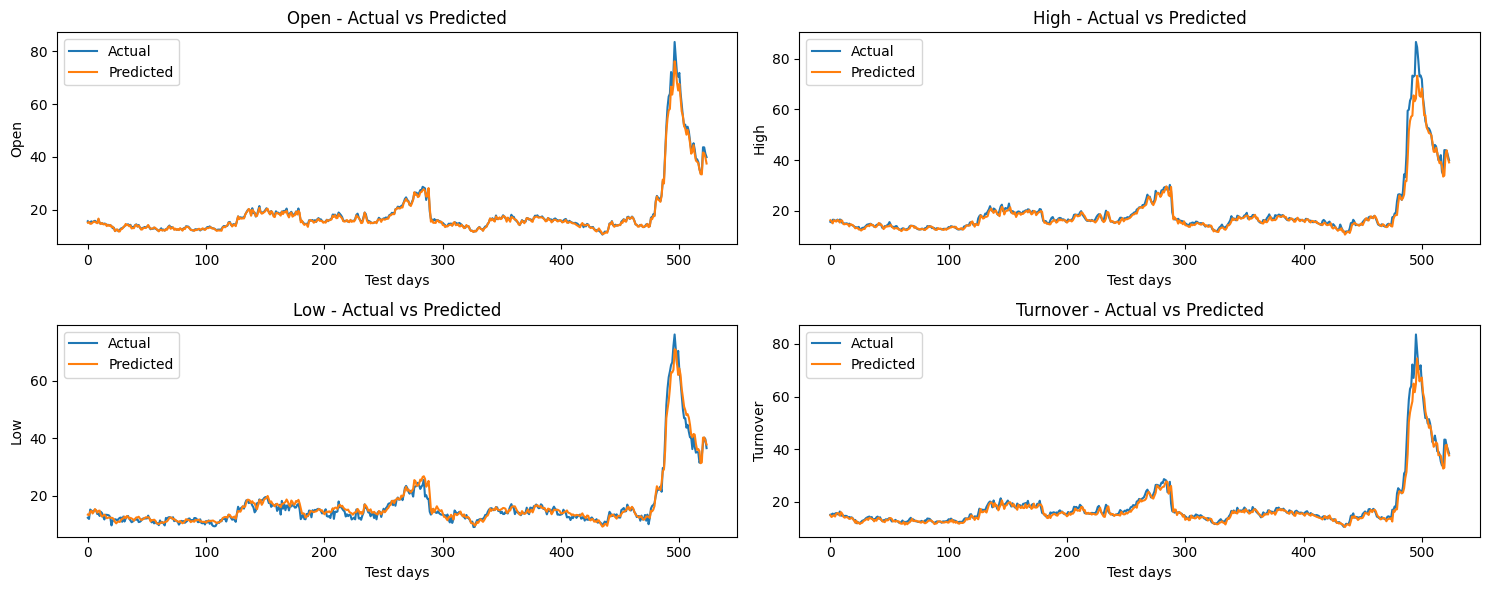

In [118]:
plt.figure(figsize=(15,6))

for i, col in enumerate(columns):
    plt.subplot(2,2,i+1)
    plt.plot(actual[:,i], label='Actual')
    plt.plot(predictions[:,i], label='Predicted')
    plt.title(f'{col} - Actual vs Predicted')
    plt.xlabel('Test days')
    plt.ylabel(col)
    plt.legend()

plt.tight_layout()
plt.show()